In [1]:
import tensorflow as tf
import os
print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU Available: []


In [2]:
dataset_root = r"C:\Users\Admin\IVP PROJECT\MRI Scan Dataset"
for folder in ["Training", "Testing"]:
    folder_path = os.path.join(dataset_root, folder)
    print(f"\n=== {folder} ===")
    for subfolder in os.listdir(folder_path):
        sub_path = os.path.join(folder_path, subfolder)
        if os.path.isdir(sub_path):
            print(subfolder, ":", len(os.listdir(sub_path)))


=== Training ===
glioma : 1321
meningioma : 1339
notumor : 1595
pituitary : 1457

=== Testing ===
glioma : 300
meningioma : 306
notumor : 405
pituitary : 300


In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
dataset_root = r"C:\Users\Admin\IVP PROJECT\MRI Scan Dataset"
train_dir = os.path.join(dataset_root, "Training")
test_dir = os.path.join(dataset_root, "Testing")
IMG_SIZE = (150, 150)
BATCH = 32
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)
test_datagen = ImageDataGenerator(rescale=1./255)
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical'
)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical'
)
print("\nClass indices:", train_data.class_indices)

Found 5712 images belonging to 4 classes.
Found 1311 images belonging to 4 classes.

Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [4]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(150,150,3)),        # Correct way to define input
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(4, activation='softmax')  # For 4 classes
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',        # Use 'sparse_categorical_crossentropy' if labels are integers
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 72, 72, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 34, 34, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 17, 17, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 36992)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       4,735,104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,828,868 (18.42 MB)

 Trainable params: 4,828,868 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
import os, shutil

dataset_root = r"C:\Users\Admin\IVP PROJECT\MRI Scan Dataset"

removed = 0
for root, dirs, files in os.walk(dataset_root):
    if '.ipynb_checkpoints' in dirs:
        path = os.path.join(root, '.ipynb_checkpoints')
        print("Removing:", path)
        shutil.rmtree(path)
        removed += 1
print(f"Removed {removed} .ipynb_checkpoints folders.\n")

# STEP 2: Verify folder counts (optional but useful)
for split in ["Training", "Testing"]:
    print(f"--- {split} ---")
    split_path = os.path.join(dataset_root, split)
    for cls in ["glioma","meningioma","notumor","pituitary"]:
        cls_path = os.path.join(split_path, cls)
        if os.path.isdir(cls_path):
            print(f"{cls}: {len([f for f in os.listdir(cls_path) if os.path.isfile(os.path.join(cls_path,f))])}")
        else:
            print(f"{cls}: MISSING -> check folder path!")

# STEP 3: Recreate generators with explicit class order
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (150,150)
BATCH = 32
class_names = ['glioma','meningioma','notumor','pituitary']  # explicit order

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_dir = os.path.join(dataset_root, "Training")
test_dir  = os.path.join(dataset_root, "Testing")

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical',
    classes=class_names,
    shuffle=True,
    seed=42
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical',
    classes=class_names,
    shuffle=False
)

print("\nFinal class indices:", train_data.class_indices)


Removed 0 .ipynb_checkpoints folders.

--- Training ---
glioma: 1321
meningioma: 1339
notumor: 1595
pituitary: 1457
--- Testing ---
glioma: 300
meningioma: 306
notumor: 405
pituitary: 300
Found 5712 images belonging to 4 classes.
Found 1311 images belonging to 4 classes.

Final class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [6]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# STEP 2: Define callbacks
early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=3,              # stop after 3 epochs of no improvement
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_mri_tumor_model.h5",  # saves best model automatically
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# STEP 3: Train the model
EPOCHS = 20

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=EPOCHS,
    callbacks=[early_stop, checkpoint]
)


C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5198 - loss: 1.0475
Epoch 1: val_accuracy improved from None to 0.58505, saving model to best_mri_tumor_model.h5


179/179 ━━━━━━━━━━━━━━━━━━━━ 234s 1s/step - accuracy: 0.6257 - loss: 0.8738 - val_accuracy: 0.5850 - val_loss: 1.2041
Epoch 2/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7142 - loss: 0.6941
Epoch 2: val_accuracy improved from 0.58505 to 0.72082, saving model to best_mri_tumor_model.h5


179/179 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - accuracy: 0.7337 - loss: 0.6586 - val_accuracy: 0.7208 - val_loss: 0.7496
Epoch 3/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7650 - loss: 0.5870
Epoch 3: val_accuracy improved from 0.72082 to 0.74447, saving model to best_mri_tumor_model.h5


179/179 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - accuracy: 0.7700 - loss: 0.5740 - val_accuracy: 0.7445 - val_loss: 0.6360
Epoch 4/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8081 - loss: 0.5242
Epoch 4: val_accuracy improved from 0.74447 to 0.77651, saving model to best_mri_tumor_model.h5


179/179 ━━━━━━━━━━━━━━━━━━━━ 757s 4s/step - accuracy: 0.8048 - loss: 0.5203 - val_accuracy: 0.7765 - val_loss: 0.5557
Epoch 5/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 640ms/step - accuracy: 0.8001 - loss: 0.5166
Epoch 5: val_accuracy did not improve from 0.77651
179/179 ━━━━━━━━━━━━━━━━━━━━ 123s 689ms/step - accuracy: 0.8083 - loss: 0.4976 - val_accuracy: 0.5515 - val_loss: 1.9238
Epoch 6/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 751ms/step - accuracy: 0.8114 - loss: 0.4991
Epoch 6: val_accuracy did not improve from 0.77651
179/179 ━━━━━━━━━━━━━━━━━━━━ 145s 807ms/step - accuracy: 0.8207 - loss: 0.4694 - val_accuracy: 0.7498 - val_loss: 0.7521
Epoch 7/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 701ms/step - accuracy: 0.8299 - loss: 0.4523
Epoch 7: val_accuracy improved from 0.77651 to 0.79558, saving model to best_mri_tumor_model.h5


179/179 ━━━━━━━━━━━━━━━━━━━━ 136s 760ms/step - accuracy: 0.8283 - loss: 0.4457 - val_accuracy: 0.7956 - val_loss: 0.5381
Epoch 8/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 576ms/step - accuracy: 0.8387 - loss: 0.4127
Epoch 8: val_accuracy improved from 0.79558 to 0.82456, saving model to best_mri_tumor_model.h5


179/179 ━━━━━━━━━━━━━━━━━━━━ 110s 615ms/step - accuracy: 0.8349 - loss: 0.4203 - val_accuracy: 0.8246 - val_loss: 0.4309
Epoch 9/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 565ms/step - accuracy: 0.8388 - loss: 0.4104
Epoch 9: val_accuracy did not improve from 0.82456
179/179 ━━━━━━━━━━━━━━━━━━━━ 106s 593ms/step - accuracy: 0.8416 - loss: 0.4106 - val_accuracy: 0.7582 - val_loss: 0.7388
Epoch 10/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 568ms/step - accuracy: 0.8557 - loss: 0.3946
Epoch 10: val_accuracy did not improve from 0.82456
179/179 ━━━━━━━━━━━━━━━━━━━━ 109s 610ms/step - accuracy: 0.8575 - loss: 0.3843 - val_accuracy: 0.7849 - val_loss: 0.4932
Epoch 11/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 689ms/step - accuracy: 0.8557 - loss: 0.3747
Epoch 11: val_accuracy did not improve from 0.82456
179/179 ━━━━━━━━━━━━━━━━━━━━ 134s 748ms/step - accuracy: 0.8633 - loss: 0.3515 - val_accuracy: 0.8207 - val_loss: 0.4172


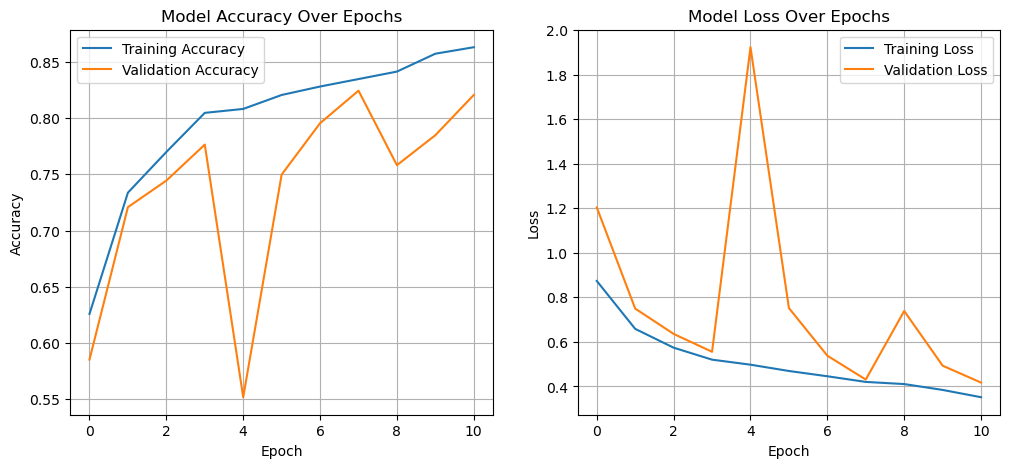

In [7]:
import matplotlib.pyplot as plt

# Step 3: Plot training vs validation accuracy
plt.figure(figsize=(12,5))

# Accuracy plot
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()


In [8]:
# Evaluate the trained model on test data
print("Evaluating model on test set...")

test_loss, test_accuracy = model.evaluate(test_data, verbose=1)

print(f"\n Test Accuracy: {test_accuracy*100:.2f}%")
print(f" Test Loss: {test_loss:.4f}")

Evaluating model on test set...
41/41 ━━━━━━━━━━━━━━━━━━━━ 6s 153ms/step - accuracy: 0.8246 - loss: 0.4309

 Test Accuracy: 82.46%
 Test Loss: 0.4309


In [9]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate predictions
print("Generating predictions...")

test_data.reset()  # Reset generator to start from beginning
predictions = model.predict(test_data, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_data.classes

print(f"\n✅ Generated {len(predictions)} predictions")

Generating predictions...
41/41 ━━━━━━━━━━━━━━━━━━━━ 7s 159ms/step

✅ Generated 1311 predictions


In [10]:
# Detailed classification report
print("\n Classification Report:\n")

class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

report = classification_report(
    true_classes, 
    predicted_classes, 
    target_names=class_names,
    digits=4
)

print(report)


 Classification Report:

              precision    recall  f1-score   support

      glioma     0.8433    0.7533    0.7958       300
  meningioma     0.7098    0.5196    0.6000       306
     notumor     0.8204    0.9926    0.8983       405
   pituitary     0.8936    0.9800    0.9348       300

    accuracy                         0.8246      1311
   macro avg     0.8168    0.8114    0.8072      1311
weighted avg     0.8166    0.8246    0.8136      1311



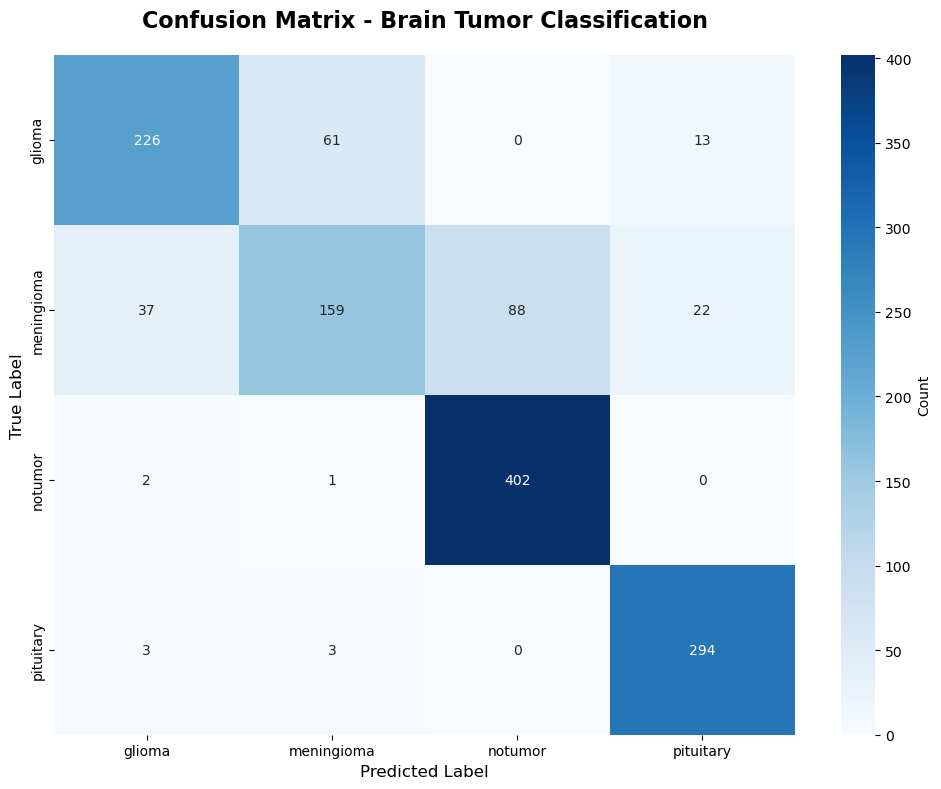


✅ Confusion matrix saved as 'confusion_matrix.png'


In [11]:
# Create confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names,
            cbar_kws={'label': 'Count'})

plt.title('Confusion Matrix - Brain Tumor Classification', 
          fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()

# Save the plot
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Confusion matrix saved as 'confusion_matrix.png'")

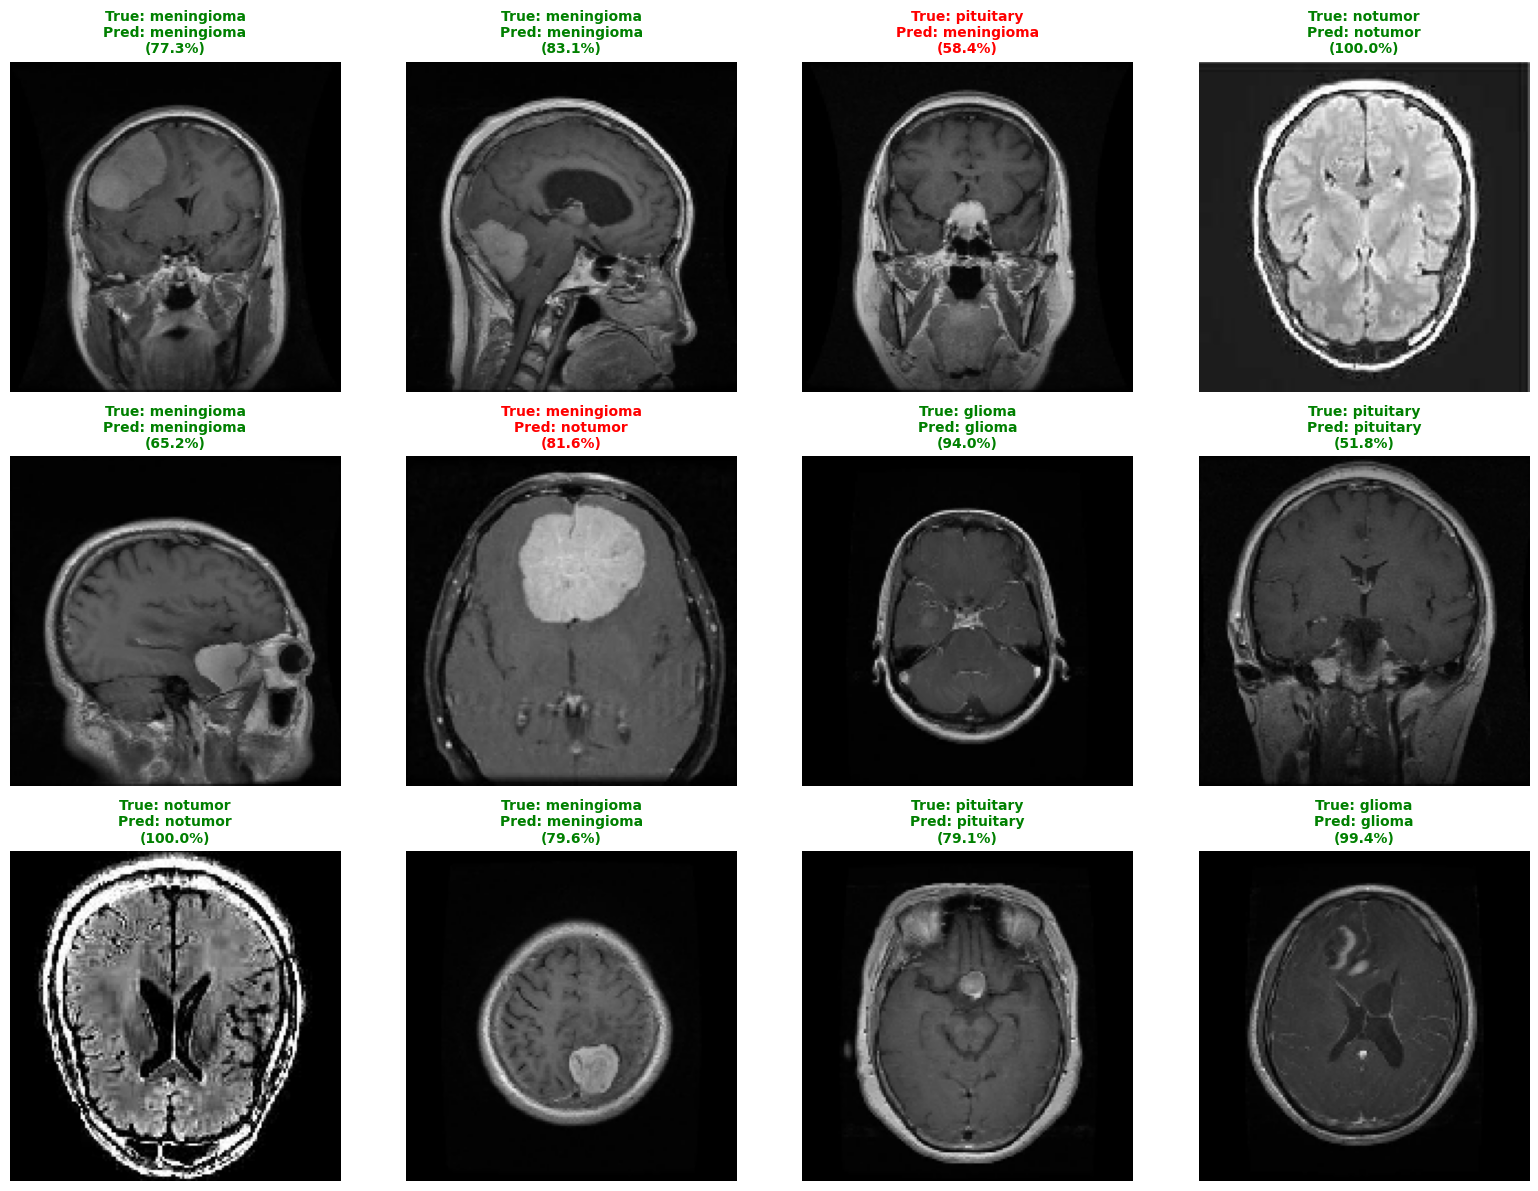


✅ Sample predictions saved as 'sample_predictions.png'


In [12]:
import random

plt.figure(figsize=(16, 12))

# Get random samples
num_samples = 12
test_data.reset()
sample_indices = random.sample(range(len(test_data.filenames)), num_samples)

for idx, sample_idx in enumerate(sample_indices):
    # FIXED: Build the correct full path
    img_path = os.path.join(test_data.directory, test_data.filenames[sample_idx])
    
    # Load image
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0
    
    # Predict
    pred = model.predict(img_array, verbose=0)
    pred_class = class_names[np.argmax(pred)]
    true_class = class_names[test_data.classes[sample_idx]]
    confidence = np.max(pred) * 100
    
    # Plot
    plt.subplot(3, 4, idx + 1)
    plt.imshow(img)
    
    # Color: green if correct, red if wrong
    color = 'green' if pred_class == true_class else 'red'
    plt.title(f'True: {true_class}\nPred: {pred_class}\n({confidence:.1f}%)', 
              color=color, fontsize=10, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.savefig('sample_predictions.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Sample predictions saved as 'sample_predictions.png'")

In [13]:
model.save("mri_scan_tumor_detector.h5")

In [ ]:
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import tkinter as tk
from tkinter import filedialog
from PIL import Image, ImageTk

# Load your trained model (adjust filename if different)
model = load_model('brain_tumor_detector.h5')

# Class names consistent with training
classnames = ['glioma', 'meningioma', 'notumor', 'pituitary']

def preprocess_image(image_path):
    img = load_img(image_path, target_size=(150, 150))
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    return img_array

def predict_image(image_path):
    img_array = preprocess_image(image_path)
    prediction = model.predict(img_array)
    class_idx = np.argmax(prediction)
    confidence = np.max(prediction)
    return classnames[class_idx], confidence

def upload_and_predict():
    # Open file dialog to select image
    filepath = filedialog.askopenfilename()
    if filepath:
        class_name, confidence = predict_image(filepath)
        result_text.set(f"Prediction: {class_name} ({confidence*100:.2f}%)")
        # Display image
        img = Image.open(filepath)
        img.thumbnail((250, 250))
        img_tk = ImageTk.PhotoImage(img)
        image_label.config(image=img_tk)
        image_label.image = img_tk

# Setup tkinter GUI
root = tk.Tk()
root.title("Brain Tumor Detection")

btn = tk.Button(root, text="Upload MRI Image", command=upload_and_predict)
btn.pack(pady=10)

result_text = tk.StringVar()
result_label = tk.Label(root, textvariable=result_text, font=('Arial', 14))
result_label.pack(pady=10)

image_label = tk.Label(root)
image_label.pack()

root.mainloop()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
